# Decision Tree 
## PART 1 – UNDERSTANDING DECISION TREE

### 1. What is a Decision Tree?
A Decision Tree is a supervised machine learning algorithm used for:
1. Classification – predicting categorical outputs.
2. Regression – predicting continuous numerical outputs.

It works by repeatedly splitting a dataset into smaller groups based on conditions applied to input features, creating a tree-like structure of decisions.

**Real-world industry examples:**
- Banking: Loan approval (Approve / Reject), Fraud detection
- Healthcare: Disease diagnosis
- Retail: Customer churn, Product demand
- Real Estate: Property valuation

### 2. Why is it called a Decision Tree?
It resembles a tree with a starting point (root), decision conditions (internal nodes), branches (outcomes), and final outputs (leaf nodes).

### 3. Important Components of a Decision Tree
- **Root Node**: First node representing the initial feature and split condition.
- **Decision/Internal Node**: Node where further conditions are applied.
- **Branch**: Outcome of a decision (e.g., Yes/No).
- **Leaf Node**: Final node producing the prediction.
- **Parent/Child Node**: Source and resulting nodes of a split.
- **Depth**: Number of levels from root to a node.

### 4. How Does a Decision Tree Work?
1. Evaluates possible features and split conditions.
2. Measures split quality using an impurity criterion.
3. Selects the best split to divide the dataset into child groups.
4. Recursively splits until a stopping condition is reached.


---
## PART 2 – MATHEMATICS BEHIND DECISION TREE

### 5. What is Splitting & Node Impurity?
- **Splitting**: Dividing data based on a feature condition to create more homogeneous child nodes.
- **Node Impurity**: Measures how mixed target values are in a node.

### 6. Gini Impurity vs Entropy

#### Gini Impurity
Formula:
$$\text{Gini} = 1 - \sum p_i^2$$
- Pure node: $\text{Gini} = 0$
- Maximum impurity (binary): $\text{Gini} = 0.5$

#### Entropy
Formula:
$$\text{Entropy} = -\sum p_i \log_2(p_i)$$
- Pure node: $\text{Entropy} = 0$
- Maximum uncertainty (binary): $\text{Entropy} = 1.0$

### 7. Information Gain
Formula:
$$\text{Information Gain} = \text{Parent Entropy} - \text{Weighted Child Entropy}$$


In [1]:
from sklearn.tree import DecisionTreeClassifier

# Initializing Decision Tree with Gini vs Entropy
gini_model = DecisionTreeClassifier(criterion="gini")
entropy_model = DecisionTreeClassifier(criterion="entropy")

---
## PART 3 & 4 – REGRESSION TREES & COMPARISON

### 8. Regression Decision Tree
Predicts continuous numerical values using criteria like Mean Squared Error (MSE) or Mean Absolute Error (MAE).
- **Leaf prediction with `squared_error`**: Mean of target values in the leaf.
- **Leaf prediction with `absolute_error`**: Median of target values in the leaf.

### Classifier vs Regressor Comparison

| Feature | `DecisionTreeClassifier` | `DecisionTreeRegressor` |
|---|---|---|
| Target | Categorical | Continuous numerical |
| Criteria | Gini, Entropy, Log Loss | Squared Error, Absolute Error, Friedman MSE |
| Leaf Output | Majority Class | Mean / Median Value |
| Metrics | Accuracy, Precision, Recall, F1, ROC-AUC | MAE, MSE, RMSE, R² |


---
## PART 5 – PREPROCESSING IN DECISION TREE

- **Feature Scaling**: Not required (trees use feature thresholding).
- **Encoding**: Required for string categories in Scikit-Learn.
- **Outliers**: Less sensitive than distance-based models, but can impact regression splits.


In [2]:
import pandas as pd

# Example: One-Hot Encoding for Nominal Categories
df = pd.DataFrame({
    "City": ["Pune", "Mumbai", "Delhi", "Pune"],
    "Income": [50000, 70000, 60000, 55000]
})
df_encoded = pd.get_dummies(df, columns=["City"], dtype=int)
print("Encoded DataFrame:")
print(df_encoded)

Encoded DataFrame:
   Income  City_Delhi  City_Mumbai  City_Pune
0   50000           0            0          1
1   70000           0            1          0
2   60000           1            0          0
3   55000           0            0          1


---
## PART 6, 7 & 8 – OVERFITTING, PRE-PRUNING & POST-PRUNING

- **Pre-pruning**: Stopping tree growth early (`max_depth`, `min_samples_split`, `min_samples_leaf`, `max_leaf_nodes`).
- **Post-pruning**: Allowing full growth, then trimming using Cost Complexity Pruning (`ccp_alpha`).


In [3]:
from sklearn.tree import DecisionTreeClassifier

# Demonstrating Cost Complexity Pruning Path setup
# (Requires X_train, y_train fit)
tree = DecisionTreeClassifier(random_state=42)
# path = tree.cost_complexity_pruning_path(X_train, y_train)
# ccp_alphas = path.ccp_alphas

---
## PART 11 to 14 – CROSS-VALIDATION & HYPERPARAMETER TUNING

Demonstrating `KFold`, `StratifiedKFold`, `GridSearchCV`, and `RandomizedSearchCV`.


In [4]:
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

# K-Fold & Stratified K-Fold setup
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
dt_dummy = DecisionTreeClassifier(random_state=42)

---
## PART 15 & 16 – FRAUD DETECTION CLASSIFICATION PROJECT & TUNING


In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, average_precision_score
)
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
from scipy.stats import randint, uniform

# Step 1: Create synthetic data
np.random.seed(42)
n = 10000
amount = np.random.exponential(5000, n)
account_age = np.random.randint(1, 1000, n)
failed_attempts = np.random.poisson(1, n)
international = np.random.binomial(1, 0.15, n)
unusual_time = np.random.binomial(1, 0.20, n)
device_change = np.random.binomial(1, 0.15, n)
transactions_24h = np.random.poisson(3, n)
location_change = np.random.binomial(1, 0.10, n)
distance_km = np.random.exponential(20, n)
churned_device = np.random.binomial(1, 0.05, n)

risk_score = (
    0.00015 * amount
    + 0.30 * failed_attempts
    + 0.90 * international
    + 0.80 * unusual_time
    + 0.90 * device_change
    + 0.20 * transactions_24h
    + 0.90 * location_change
    + 0.01 * distance_km
    + 1.00 * churned_device
    - 0.001 * account_age
)

fraud_probability = 1 / (1 + np.exp(-(risk_score - 3.5)))
fraud = np.random.binomial(1, fraud_probability)

df_fraud = pd.DataFrame({
    "Amount": amount,
    "Account_Age": account_age,
    "Failed_Attempts": failed_attempts,
    "International": international,
    "Unusual_Time": unusual_time,
    "Device_Change": device_change,
    "Transactions_24h": transactions_24h,
    "Location_Change": location_change,
    "Distance_KM": distance_km,
    "Churned_Device": churned_device,
    "Fraud": fraud
})

print("Fraud Dataset Head:")
print(df_fraud.head())
print("Target Class Distribution:")
print(df_fraud["Fraud"].value_counts(normalize=True))

# Step 2: Separate features and target
X_cls = df_fraud.drop("Fraud", axis=1)
y_cls = df_fraud["Fraud"]

# Step 3: Train-test split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cls, y_cls, test_size=0.20, random_state=42, stratify=y_cls
)

# Step 4: Build baseline Decision Tree Classifier
dt_cls = DecisionTreeClassifier(criterion="gini", random_state=42)
dt_cls.fit(X_train_c, y_train_c)

# Step 5: Predictions & Evaluation
y_pred_c = dt_cls.predict(X_test_c)
y_prob_c = dt_cls.predict_proba(X_test_c)[:, 1]

print("--- Baseline Classifier Evaluation ---")
print("Accuracy:", accuracy_score(y_test_c, y_pred_c))
print("Precision:", precision_score(y_test_c, y_pred_c, zero_division=0))
print("Recall:", recall_score(y_test_c, y_pred_c, zero_division=0))
print("F1 Score:", f1_score(y_test_c, y_pred_c, zero_division=0))
print("ROC AUC:", roc_auc_score(y_test_c, y_prob_c))
print("PR AUC:", average_precision_score(y_test_c, y_prob_c))

# Overfitting check
print("Train Accuracy:", accuracy_score(y_train_c, dt_cls.predict(X_train_c)))
print("Test Accuracy:", accuracy_score(y_test_c, y_pred_c))

# Feature Importance
imp_df = pd.DataFrame({
    "Feature": X_cls.columns,
    "Importance": dt_cls.feature_importances_
}).sort_values(by="Importance", ascending=False)
print("Impurity Feature Importance:", imp_df)

Fraud Dataset Head:
         Amount  Account_Age  Failed_Attempts  International  Unusual_Time  \
0   2346.340450          183                0              0             0   
1  15050.607155          864                0              1             1   
2   6583.728468          548                2              0             0   
3   4564.712769          882                2              0             1   
4    848.124352           37                2              0             0   

   Device_Change  Transactions_24h  Location_Change  Distance_KM  \
0              0                 3                0    12.790955   
1              0                 4                0    22.299349   
2              0                 2                0    11.834660   
3              0                 4                0    25.152615   
4              0                 3                1     9.820038   

   Churned_Device  Fraud  
0               0      0  
1               0      1  
2               0    

In [3]:
# Overfitting check
print("Train Accuracy:", accuracy_score(y_train_c, dt_cls.predict(X_train_c)))
print("Test Accuracy:", accuracy_score(y_test_c, y_pred_c))

# Feature Importance
imp_df = pd.DataFrame({
    "Feature": X_cls.columns,
    "Importance": dt_cls.feature_importances_
}).sort_values(by="Importance", ascending=False)
print("Impurity Feature Importance:", imp_df)

Train Accuracy: 1.0
Test Accuracy: 0.7235
Impurity Feature Importance:             Feature  Importance
0            Amount    0.296910
1       Account_Age    0.227562
8       Distance_KM    0.227127
6  Transactions_24h    0.081793
2   Failed_Attempts    0.063824
7   Location_Change    0.025533
5     Device_Change    0.020874
4      Unusual_Time    0.019832
3     International    0.018917
9    Churned_Device    0.017629


In [2]:
print("--- Baseline Classifier Evaluation ---")
print("Accuracy:", accuracy_score(y_test_c, y_pred_c))
print("Precision:", precision_score(y_test_c, y_pred_c, zero_division=0))
print("Recall:", recall_score(y_test_c, y_pred_c, zero_division=0))
print("F1 Score:", f1_score(y_test_c, y_pred_c, zero_division=0))
print("ROC AUC:", roc_auc_score(y_test_c, y_prob_c))
print("PR AUC:", average_precision_score(y_test_c, y_prob_c))

--- Baseline Classifier Evaluation ---
Accuracy: 0.7235
Precision: 0.33793103448275863
Recall: 0.3567961165048544
F1 Score: 0.34710743801652894
ROC AUC: 0.5877179574967596
PR AUC: 0.2530724807499163


In [12]:
imp_df

,Feature,Importance
0,Amount,0.296910
1,Account_Age,0.227562
8,Distance_KM,0.227127
6,Transactions_24h,0.081793
2,Failed_Attempts,0.063824
7,Location_Change,0.025533
5,Device_Change,0.020874
4,Unusual_Time,0.019832
3,International,0.018917
9,Churned_Device,0.017629


-----------------------------------------------------------------------------------------------

In [5]:
df_fraud

,Amount,Account_Age,Failed_Attempts,International,Unusual_Time,Device_Change,Transactions_24h,Location_Change,Distance_KM,Churned_Device,Fraud
0,2346.340450,183,0,0,0,0,3,0,12.790955,0,0
1,15050.607155,864,0,1,1,0,4,0,22.299349,0,1
2,6583.728468,548,2,0,0,0,2,0,11.834660,0,0
3,4564.712769,882,2,0,1,0,4,0,25.152615,0,0
4,848.124352,37,2,0,0,0,3,1,9.820038,0,1
...,...,...,...,...,...,...,...,...,...,...,...
9995,9747.542666,358,1,0,1,0,3,0,21.818906,0,1
9996,11389.893401,203,1,0,0,0,1,1,52.160971,0,0
9997,14659.837293,708,1,0,0,0,3,0,16.627492,0,0
9998,2533.238421,58,1,0,1,0,3,0,10.559848,0,0


In [4]:
# check for data leakage # execute this cell separately

# Step 2: Separate features and target
X_cls = df_fraud
y_cls = df_fraud["Fraud"]

# Step 3: Train-test split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cls, y_cls, test_size=0.20, random_state=42, stratify=y_cls
)

# Step 4: Build baseline Decision Tree Classifier
dt_cls = DecisionTreeClassifier(criterion="gini", random_state=42)
dt_cls.fit(X_train_c, y_train_c)

# Step 5: Predictions & Evaluation
y_pred_c = dt_cls.predict(X_test_c)
y_prob_c = dt_cls.predict_proba(X_test_c)[:, 1]

print("--- Baseline Classifier Evaluation ---")
print("Accuracy:", accuracy_score(y_test_c, y_pred_c))
print("Precision:", precision_score(y_test_c, y_pred_c, zero_division=0))
print("Recall:", recall_score(y_test_c, y_pred_c, zero_division=0))
print("F1 Score:", f1_score(y_test_c, y_pred_c, zero_division=0))
print("ROC AUC:", roc_auc_score(y_test_c, y_prob_c))
print("PR AUC:", average_precision_score(y_test_c, y_prob_c))

# Overfitting check
print("Train Accuracy:", accuracy_score(y_train_c, dt_cls.predict(X_train_c)))
print("Test Accuracy:", accuracy_score(y_test_c, y_pred_c))

# Feature Importance
imp_df = pd.DataFrame({
    "Feature": X_cls.columns,
    "Importance": dt_cls.feature_importances_
}).sort_values(by="Importance", ascending=False)
print("Impurity Feature Importance:", imp_df)

--- Baseline Classifier Evaluation ---
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
ROC AUC: 1.0
PR AUC: 1.0
Train Accuracy: 1.0
Test Accuracy: 1.0
Impurity Feature Importance:              Feature  Importance
10             Fraud         1.0
1        Account_Age         0.0
0             Amount         0.0
2    Failed_Attempts         0.0
3      International         0.0
5      Device_Change         0.0
4       Unusual_Time         0.0
6   Transactions_24h         0.0
7    Location_Change         0.0
8        Distance_KM         0.0
9     Churned_Device         0.0


In [15]:
imp_df

,Feature,Importance
10,Fraud,1.0
0,Amount,0.0
1,Account_Age,0.0
2,Failed_Attempts,0.0
3,International,0.0
4,Unusual_Time,0.0
5,Device_Change,0.0
6,Transactions_24h,0.0
7,Location_Change,0.0
8,Distance_KM,0.0


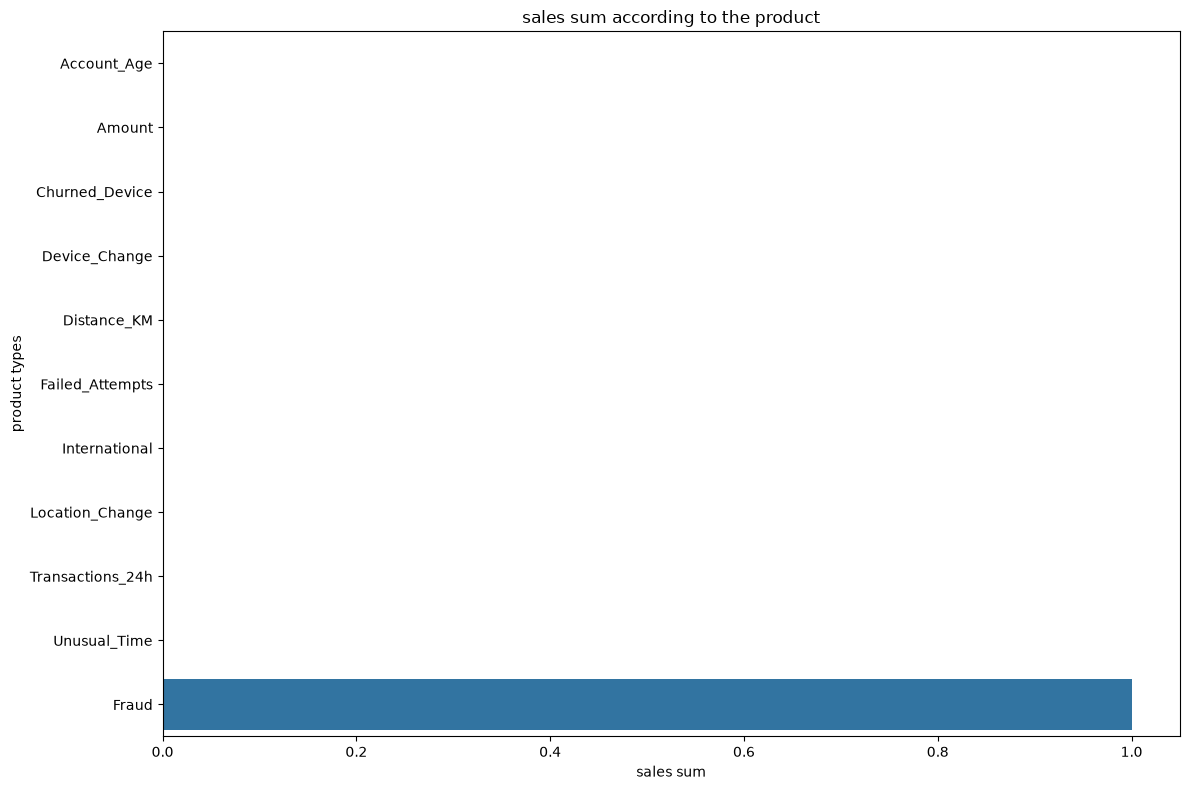

In [16]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,8))

category_sales = imp_df.groupby('Feature')['Importance'].sum().sort_values(ascending = True)
sns.barplot(
    y= category_sales.index,
    x=category_sales.values
)
plt.title("sales sum according to the product")
plt.xlabel("sales sum")
plt.ylabel("product types")


plt.tight_layout()
plt.show()

--------------------------

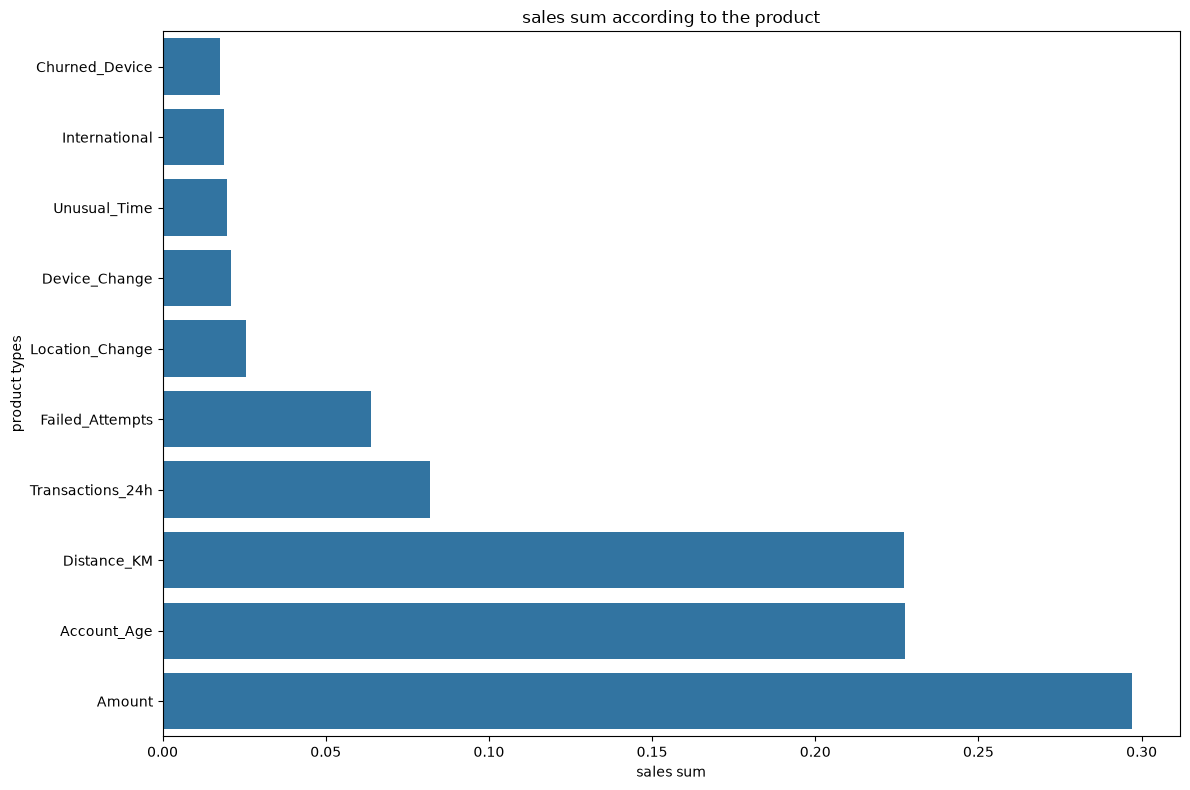

In [13]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,8))

category_sales = imp_df.groupby('Feature')['Importance'].sum().sort_values(ascending = True)
sns.barplot(
    y= category_sales.index,
    x=category_sales.values
)
plt.title("sales sum according to the product")
plt.xlabel("sales sum")
plt.ylabel("product types")


plt.tight_layout()
plt.show()

-------------------------------------------------------------------------------------------------

In [ ]:
# Hyperparameter Tuning with GridSearchCV (Compact set for execution efficiency)
param_grid_c = {
    "criterion": ["gini", "entropy"],
    "max_depth": [5, 8, 10],
    "min_samples_split": [10, 20],
    "min_samples_leaf": [5, 10],
    "class_weight": [None, "balanced"],
    "max_features" :['sqrt','log2']
    #"min_impurity_decrease"
}

cv_strat = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_c = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_c,
    cv=cv_strat,
    scoring="f1",
    n_jobs=-1
)
grid_c.fit(X_train_c, y_train_c)

print("Best Parameters (GridSearch):", grid_c.best_params_)
print("Best CV F1:", grid_c.best_score_)

best_dt_c = grid_c.best_estimator_
best_pred_c = best_dt_c.predict(X_test_c)
print("Tuned Model Test F1:", f1_score(y_test_c, best_pred_c, zero_division=0))

Best Parameters (GridSearch): {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 5, 'min_samples_split': 20}
Best CV F1: 0.4463031268066864
Tuned Model Test F1: 0.42304230423042305


---
## PART 17 & 18 – HOUSE PRICE REGRESSION PROJECT & TUNING


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Step 1: Create synthetic regression dataset
np.random.seed(42)
n_reg = 5000
area = np.random.randint(500, 3500, n_reg)
bedrooms = np.random.randint(1, 6, n_reg)
age = np.random.randint(1, 40, n_reg)
distance = np.random.uniform(1, 30, n_reg)
parking = np.random.binomial(1, 0.6, n_reg)

price = (
    0.05 * area
    + 8 * bedrooms
    - 0.5 * age
    - 1.2 * distance
    + 5 * parking
    + np.random.normal(0, 8, n_reg)
)

df_reg = pd.DataFrame({
    "Area": area,
    "Bedrooms": bedrooms,
    "Age": age,
    "Distance": distance,
    "Parking": parking,
    "Price": price
})

# Step 2: Separate X and y
X_reg = df_reg.drop("Price", axis=1)
y_reg = df_reg["Price"]

# Step 3: Train-test split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

# Step 4: Train Decision Tree Regressor
dt_reg = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
dt_reg.fit(X_train_r, y_train_r)

# Step 5: Evaluate Regressor
y_pred_r = dt_reg.predict(X_test_r)

print("--- Regressor Evaluation ---")
print("MAE:", mean_absolute_error(y_test_r, y_pred_r))
print("MSE:", mean_squared_error(y_test_r, y_pred_r))
print("RMSE:", np.sqrt(mean_squared_error(y_test_r, y_pred_r)))
print("R2 Score:", r2_score(y_test_r, y_pred_r))

# Step 6: GridSearchCV for Regressor
param_grid_r = {
    "criterion": ["squared_error", "friedman_mse", "absolute_error"],
    "max_depth": [3, 5, 8],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [2, 5]
}

reg_grid = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid_r,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=-1 #use all cpu for reduce time
)
reg_grid.fit(X_train_r, y_train_r)

print("Best Parameters (Regression):", reg_grid.best_params_)
print("Best CV Score (Neg MAE):", reg_grid.best_score_)

--- Regressor Evaluation ---
MAE: 11.46570044140183
MSE: 208.83900205482186
RMSE: 14.451262991684217
R2 Score: 0.9057451530937766
Best Parameters (Regression): {'criterion': 'squared_error', 'max_depth': 8, 'min_samples_leaf': 5, 'min_samples_split': 5}
Best CV Score (Neg MAE): -9.61864212003691


c:\Users\PRAJWAL\anaconda3\envs\cds_ai_python\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
36 fits failed out of a total of 108.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
12 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\PRAJWAL\anaconda3\envs\cds_ai_python\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\PRAJWAL\anaconda3\envs\cds_ai_python\Lib\site-packages\sklearn\base.py", line 1393, in wrapper
    estimator._validate_params()
  File "c:\Users\PRAJWAL\anaconda3\envs\cds_ai_python\Lib\site-packages\sklearn\base.py", line 554, in _validate_params
  

: 